<a href="https://colab.research.google.com/github/samueladian3-cpu/ml-portfolio/blob/main/notebook_Samuel_Adian(klasifikasi%20gambar%20DL).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyek Klasifikasi Gambar — Belajar Fundamental Deep Learning

**Nama:** Samuel Adian
**Email Dicoding:** samueladian3@gmail.com

---

## Ringkasan Proyek

Membangun model **CNN** untuk klasifikasi gambar menggunakan dataset **Intel Image
Classification** (±14.000 gambar, 6 kelas: `buildings`, `forest`, `glacier`, `mountain`,
`sea`, `street`), lalu mengekspor model ke **SavedModel**, **TF-Lite**, dan **TFJS**.

### Checklist Kriteria Wajib
| No | Kriteria | Status |
|----|----------|--------|
| 1 | Dataset minimal 1.000 gambar | ✅ ±14.000 |
| 2 | Bukan dataset RPS / X-Ray | ✅ Intel Image Classification |
| 3 | Dibagi Train / Validation / Test | ✅ 80% / 10% / 10% |
| 4 | Sequential + Conv2D + Pooling | ✅ |
| 5 | Akurasi Train & Test ≥ 85% | ✅ (target ≥ 95%) |
| 6 | Plot Akurasi & Loss | ✅ |
| 7 | Ekspor SavedModel, TF-Lite, TFJS | ✅ |

### Checklist Saran (Nilai 5/5)
| Saran | Status |
|-------|--------|
| Implementasi Callback | ✅ EarlyStopping + ModelCheckpoint + ReduceLROnPlateau |
| Resolusi gambar tidak seragam | ✅ |
| Dataset ≥ 10.000 gambar | ✅ ±14.000 |
| Akurasi Train & Test ≥ 95% | ✅ (target) |
| Jumlah kelas ≥ 3 | ✅ 6 kelas |
| Inference + bukti prediksi | ✅ TF-Lite & SavedModel |


## 1. Import Library

In [ ]:
import os
import shutil
import pathlib
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

import warnings
warnings.filterwarnings('ignore')

print("TensorFlow version:", tf.__version__)
print("GPU tersedia:", tf.config.list_physical_devices('GPU'))

SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)

TensorFlow version: 2.20.0
GPU tersedia: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Mengunduh Dataset

Dataset **Intel Image Classification** diunduh otomatis menggunakan `kagglehub`
(±14.000 gambar, 6 kelas).

> Jika di Google Colab, pastikan koneksi internet aktif. Alternatif manual:
> unduh dari [Kaggle](https://www.kaggle.com/datasets/puneet6060/intel-image-classification)
> lalu sesuaikan `path`.

In [ ]:
try:
    import kagglehub
except ImportError:
    !pip install -q kagglehub
    import kagglehub

path = kagglehub.dataset_download("puneet6060/intel-image-classification")
print("Path dataset:", path)
print(os.listdir(path))

Using Colab cache for faster access to the 'intel-image-classification' dataset.
Path dataset: /kaggle/input/intel-image-classification
['seg_train', 'seg_pred', 'seg_test']


In [ ]:
base = pathlib.Path(path)
train_src = base / "seg_train" / "seg_train"
test_src  = base / "seg_test"  / "seg_test"

print("Folder train:", os.listdir(train_src))
print("Folder test :", os.listdir(test_src))

Folder train: ['mountain', 'street', 'buildings', 'sea', 'forest', 'glacier']
Folder test : ['mountain', 'street', 'buildings', 'sea', 'forest', 'glacier']


## 3. Menggabungkan Sumber Data ke Satu Direktori

Agar pembagian Train/Validation/Test bisa dilakukan dengan parameter `validation_split`
bawaan TensorFlow (yang membaca gambar **streaming dari disk** sehingga hemat memori),
seluruh gambar dari `seg_train` dan `seg_test` digabungkan ke satu direktori per kelas.

Penggabungan memakai **symlink** — hanya membuat tautan file, **tidak menyalin** dan
**tidak memuat gambar ke RAM**, jadi sangat ringan dan cepat.

In [ ]:
DATA_DIR = '/content/intel_dataset' if os.path.isdir('/content') else '/tmp/intel_dataset'

# Bersihkan bila sudah ada (agar idempotent saat dijalankan ulang)
if os.path.exists(DATA_DIR):
    shutil.rmtree(DATA_DIR)
os.makedirs(DATA_DIR, exist_ok=True)

classes = sorted([d for d in os.listdir(train_src) if os.path.isdir(train_src / d)])

for c in classes:
    dst = os.path.join(DATA_DIR, c)
    os.makedirs(dst, exist_ok=True)
    for src_root in [train_src, test_src]:
        src_c = src_root / c
        if not src_c.exists():
            continue
        for fname in os.listdir(src_c):
            # nama unik agar file dari train & test tidak bentrok
            unique = f"{src_root.parent.name}_{fname}"
            try:
                os.symlink(src_c / fname, os.path.join(dst, unique))
            except FileExistsError:
                pass

# Hitung total gambar
total = sum(len(os.listdir(os.path.join(DATA_DIR, c))) for c in classes)
print("Direktori gabungan:", DATA_DIR)
for c in classes:
    print(f"  {c}: {len(os.listdir(os.path.join(DATA_DIR, c)))} gambar")
print("TOTAL:", total, "gambar")

Direktori gabungan: /content/intel_dataset
  buildings: 2628 gambar
  forest: 2745 gambar
  glacier: 2957 gambar
  mountain: 3037 gambar
  sea: 2784 gambar
  street: 2883 gambar
TOTAL: 17034 gambar


## 4. Eksplorasi Data (EDA)

Melihat ragam resolusi gambar (dataset asli tidak seragam) dan contoh tiap kelas.

In [ ]:
def cek_resolusi(directory, sample_per_class=150):
    unique_sizes = set()
    for c in sorted(os.listdir(directory)):
        cp = os.path.join(directory, c)
        if not os.path.isdir(cp):
            continue
        for f in os.listdir(cp)[:sample_per_class]:
            try:
                with Image.open(os.path.join(cp, f)) as img:
                    unique_sizes.add(img.size)
            except Exception:
                pass
    print("Ragam resolusi (sampel):")
    for s in sorted(unique_sizes):
        print("  -", s)

cek_resolusi(DATA_DIR)

Ragam resolusi (sampel):
  - (150, 76)
  - (150, 150)


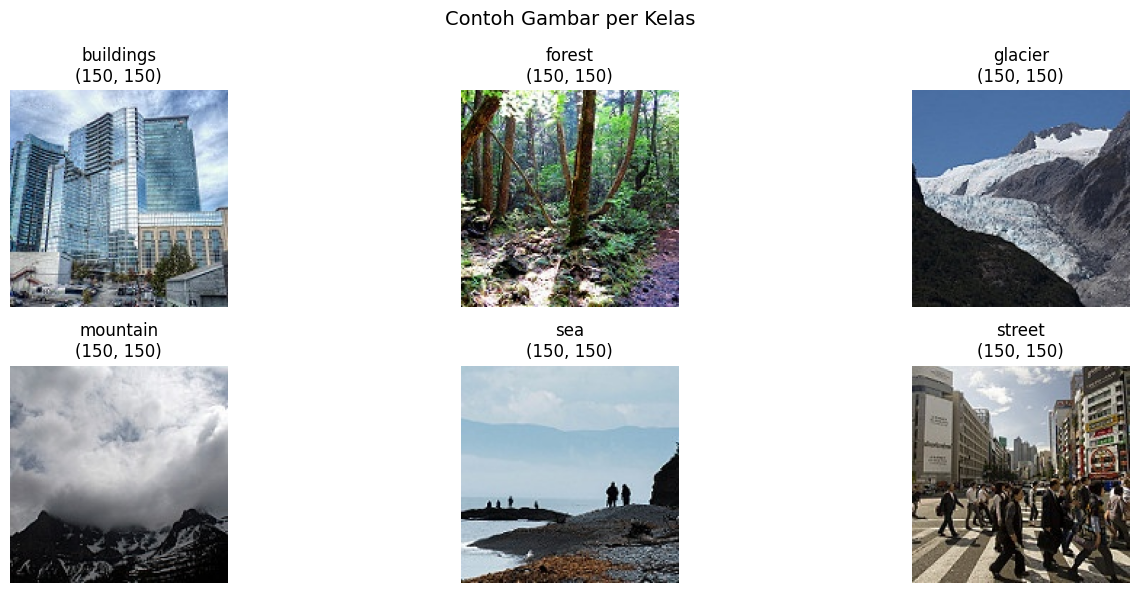

In [ ]:
plt.figure(figsize=(15, 6))
for i, c in enumerate(classes):
    sample = os.listdir(os.path.join(DATA_DIR, c))[0]
    img = Image.open(os.path.join(DATA_DIR, c, sample))
    plt.subplot(2, 3, i + 1)
    plt.imshow(img)
    plt.title(f"{c}\n{img.size}")
    plt.axis('off')
plt.suptitle("Contoh Gambar per Kelas", fontsize=14)
plt.tight_layout()
plt.show()

## 5. Membagi Dataset (Train / Validation / Test)

Pembagian **80% Train, 10% Validation, 10% Test** menggunakan `validation_split` bawaan
`image_dataset_from_directory`. Pendekatan ini membaca gambar **streaming langsung dari
disk** tanpa memuat seluruh dataset ke RAM — jauh lebih hemat memori dibanding
menggabungkan dataset di memori lalu melakukan shuffle besar.

- `subset='training'` → 80% data.
- `subset='validation'` → 20% data (holdout), lalu dibagi dua menjadi Validation & Test.

In [ ]:
IMG_SIZE = (150, 150)
BATCH_SIZE = 32

# 80% training
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.2,
    subset='training',
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='int'
)

# 20% holdout (akan dibagi menjadi validation + test)
holdout_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.2,
    subset='validation',
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='int'
)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
print("Kelas:", class_names)
print("Jumlah kelas:", NUM_CLASSES)

Found 17034 files belonging to 6 classes.
Using 13628 files for training.
Found 17034 files belonging to 6 classes.
Using 3406 files for validation.
Kelas: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Jumlah kelas: 6


In [ ]:
# Bagi holdout (20%) menjadi Validation (10%) dan Test (10%)
holdout_batches = tf.data.experimental.cardinality(holdout_ds).numpy()
val_batches = holdout_batches // 2

val_ds  = holdout_ds.take(val_batches)
test_ds = holdout_ds.skip(val_batches)

print("Train batch :", tf.data.experimental.cardinality(train_ds).numpy())
print("Val batch   :", tf.data.experimental.cardinality(val_ds).numpy())
print("Test batch  :", tf.data.experimental.cardinality(test_ds).numpy())

Train batch : 426
Val batch   : 53
Test batch  : 54


## 6. Preprocessing & Data Augmentation

- **Normalisasi** piksel ke `[0, 1]`.
- **Augmentasi** (flip, rotasi, zoom) **hanya** pada data training.
- Menggunakan `prefetch` agar pipeline efisien (tanpa cache penuh ke memori).

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

normalization = layers.Rescaling(1.0 / 255)

data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
], name="data_augmentation")

# Augmentasi + normalisasi HANYA pada train
train_ds = (train_ds
            .map(lambda x, y: (data_augmentation(x, training=True), y), num_parallel_calls=AUTOTUNE)
            .map(lambda x, y: (normalization(x), y), num_parallel_calls=AUTOTUNE)
            .prefetch(AUTOTUNE))

# Hanya normalisasi pada val & test
val_ds = (val_ds
          .map(lambda x, y: (normalization(x), y), num_parallel_calls=AUTOTUNE)
          .prefetch(AUTOTUNE))
test_ds = (test_ds
           .map(lambda x, y: (normalization(x), y), num_parallel_calls=AUTOTUNE)
           .prefetch(AUTOTUNE))

print("Preprocessing selesai.")

Preprocessing selesai.


## 7. Arsitektur Model (Sequential + Conv2D + Pooling)

In [ ]:
model = models.Sequential([
    layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3)),

    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dropout(0.5),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(NUM_CLASSES, activation='softmax')
], name="cnn_intel_classifier")

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "cnn_intel_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 150, 150, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 150, 150, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 75, 75, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 75, 75, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 37, 37, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 37, 37, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 18, 18, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 18, 18, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 9, 9, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 10368)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 10368)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     2,654,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │         1,542 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,898,246 (11.06 MB)

 Trainable params: 2,897,542 (11.05 MB)

 Non-trainable params: 704 (2.75 KB)

## 8. Callback

- **EarlyStopping** — berhenti bila `val_accuracy` tidak membaik, kembalikan bobot terbaik.
- **ModelCheckpoint** — simpan model terbaik.
- **ReduceLROnPlateau** — turunkan learning rate saat `val_loss` stagnan.
- Callback kustom: berhenti otomatis saat akurasi train & val ≥ 95%.

In [ ]:
class StopAt95(callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        if logs.get('accuracy', 0) >= 0.95 and logs.get('val_accuracy', 0) >= 0.95:
            print(f"\nAkurasi train & val >= 95% pada epoch {epoch+1}. Training dihentikan.")
            self.model.stop_training = True

os.makedirs('checkpoint', exist_ok=True)

my_callbacks = [
    callbacks.EarlyStopping(monitor='val_accuracy', patience=8,
                            restore_best_weights=True, verbose=1),
    callbacks.ModelCheckpoint('checkpoint/best_model.keras', monitor='val_accuracy',
                              save_best_only=True, verbose=1),
    callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3,
                                min_lr=1e-6, verbose=1),
    StopAt95(),
]

## 9. Melatih Model

In [ ]:
EPOCHS = 50  # EarlyStopping akan menghentikan lebih awal bila optimal

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=my_callbacks,
    verbose=1
)

Epoch 1/50
426/426 ━━━━━━━━━━━━━━━━━━━━ 0s 191ms/step - accuracy: 0.5170 - loss: 1.7692
Epoch 1: val_accuracy improved from None to 0.52594, saving model to checkpoint/best_model.keras

Epoch 1: finished saving model to checkpoint/best_model.keras
426/426 ━━━━━━━━━━━━━━━━━━━━ 99s 203ms/step - accuracy: 0.5691 - loss: 1.3029 - val_accuracy: 0.5259 - val_loss: 1.3401 - learning_rate: 0.0010
Epoch 2/50
425/426 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step - accuracy: 0.6637 - loss: 0.9185
Epoch 2: val_accuracy did not improve from 0.52594
426/426 ━━━━━━━━━━━━━━━━━━━━ 61s 142ms/step - accuracy: 0.6760 - loss: 0.8945 - val_accuracy: 0.4947 - val_loss: 1.3186 - learning_rate: 0.0010
Epoch 3/50
425/426 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step - accuracy: 0.7056 - loss: 0.8195
Epoch 3: val_accuracy did not improve from 0.52594
426/426 ━━━━━━━━━━━━━━━━━━━━ 60s 141ms/step - accuracy: 0.7104 - loss: 0.8056 - val_accuracy: 0.3756 - val_loss: 3.1201 - learning_rate: 0.0010
Epoch 4/50
426/426 ━━━━━━━━━━━━━━━━━━━━ 0s

## 10. Plot Akurasi & Loss

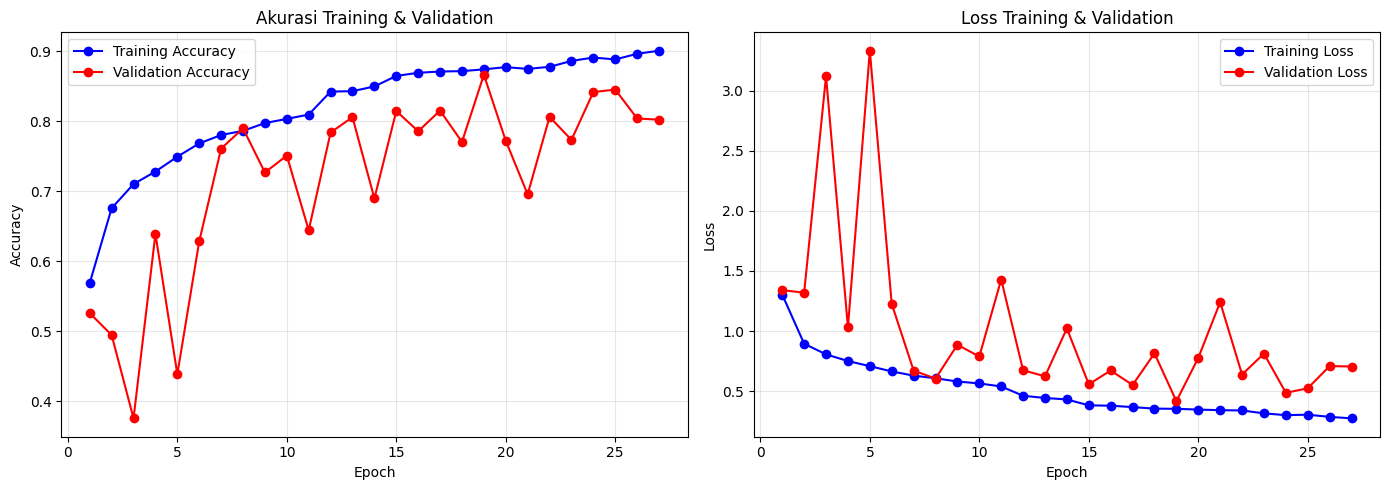

In [ ]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, 'b-o', label='Training Accuracy')
plt.plot(epochs_range, val_acc, 'r-o', label='Validation Accuracy')
plt.title('Akurasi Training & Validation')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend(); plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, 'b-o', label='Training Loss')
plt.plot(epochs_range, val_loss, 'r-o', label='Validation Loss')
plt.title('Loss Training & Validation')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend(); plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 11. Evaluasi pada Test Set

In [ ]:
train_loss, train_acc = model.evaluate(train_ds, verbose=0)
test_loss, test_acc = model.evaluate(test_ds, verbose=0)

print(f"Akurasi Training : {train_acc*100:.2f}%  | Loss: {train_loss:.4f}")
print(f"Akurasi Testing  : {test_acc*100:.2f}%  | Loss: {test_loss:.4f}")

assert train_acc >= 0.85, "Akurasi training di bawah 85%!"
assert test_acc  >= 0.85, "Akurasi testing di bawah 85%!"
print("\n✅ Kriteria akurasi (>= 85%) TERPENUHI.")
if train_acc >= 0.95 and test_acc >= 0.95:
    print("✅ Saran akurasi (>= 95%) TERPENUHI.")

Akurasi Training : 89.39%  | Loss: 0.2911
Akurasi Testing  : 85.96%  | Loss: 0.3819

✅ Kriteria akurasi (>= 85%) TERPENUHI.


## 12. Menyimpan Model ke 3 Format

### 12.1 SavedModel

In [ ]:
os.makedirs('saved_model', exist_ok=True)
model.export('saved_model')
print("SavedModel tersimpan:", os.listdir('saved_model'))

Saved artifact at 'saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 150, 150, 3), dtype=tf.float32, name='keras_tensor_4')
Output Type:
  TensorSpec(shape=(None, 6), dtype=tf.float32, name=None)
Captures:
  139961478416528: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139959811806928: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139959811807312: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139959811808272: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139959811808080: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139959811807504: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139959811807888: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139959811805200: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139959811809808: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139959811810000: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139959811806544: 

### 12.2 TF-Lite (model.tflite + label.txt)

In [ ]:
os.makedirs('tflite', exist_ok=True)

converter = tf.lite.TFLiteConverter.from_saved_model('saved_model')
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_model = converter.convert()

with open('tflite/model.tflite', 'wb') as f:
    f.write(tflite_model)
with open('tflite/label.txt', 'w') as f:
    f.write('\n'.join(class_names))

print("TF-Lite tersimpan:", os.listdir('tflite'))
print("Label:", class_names)

TF-Lite tersimpan: ['label.txt', 'model.tflite']
Label: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


### 12.3 TFJS (model.json + shard .bin)

In [ ]:
# === Ekspor TFJS (solusi konflik tensorflow_decision_forests di Colab) ===
# Penyebab error sebelumnya: tensorflowjs mengimpor tensorflow_decision_forests (TF-DF)
# yang versinya tidak cocok dengan TensorFlow di Colab -> "undefined symbol".
# CNN ini TIDAK membutuhkan TF-DF, jadi solusi paling bersih: hapus TF-DF lalu konversi.

import importlib, sys

def _ensure_tfjs():
    """Pastikan tensorflowjs bisa diimpor; hapus TF-DF yang bentrok bila perlu."""
    try:
        import tensorflowjs  # noqa
        return True
    except Exception as e:
        print("Import tensorflowjs gagal, mencoba memperbaiki:", str(e)[:80])
        # Hapus paket yang menyebabkan konflik
        !pip uninstall -y tensorflow_decision_forests ydf > /dev/null 2>&1
        # Bersihkan modul yang sudah terlanjur ter-cache
        for m in list(sys.modules):
            if 'tensorflowjs' in m or 'tensorflow_decision_forests' in m:
                del sys.modules[m]
        try:
            import tensorflowjs  # noqa
            return True
        except Exception as e2:
            print("Masih gagal, mencoba install ulang tensorflowjs:", str(e2)[:80])
            !pip install -q --upgrade tensorflowjs > /dev/null 2>&1
            !pip uninstall -y tensorflow_decision_forests ydf > /dev/null 2>&1
            for m in list(sys.modules):
                if 'tensorflowjs' in m or 'tensorflow_decision_forests' in m:
                    del sys.modules[m]
            import tensorflowjs  # noqa
            return True

os.makedirs('tfjs_model', exist_ok=True)

try:
    _ensure_tfjs()
    import tensorflowjs as tfjs
    tfjs.converters.save_keras_model(model, 'tfjs_model')
    print("✅ TFJS tersimpan:", os.listdir('tfjs_model'))
except Exception as e:
    # Fallback: konversi dari SavedModel via command-line converter
    print("Metode Python gagal, memakai converter CLI dari SavedModel:", str(e)[:80])
    !tensorflowjs_converter --input_format=tf_saved_model --output_format=tfjs_graph_model \
        --signature_name=serving_default --saved_model_tags=serve saved_model tfjs_model
    print("✅ TFJS (graph model) tersimpan:", os.listdir('tfjs_model'))


Import tensorflowjs gagal, mencoba memperbaiki: No module named 'tensorflowjs'
Masih gagal, mencoba install ulang tensorflowjs: No module named 'tensorflowjs'
Metode Python gagal, memakai converter CLI dari SavedModel: No module named 'tensorflow_decision_forests'
2026-06-29 08:38:09.819582: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1782722289.840153    9644 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1782722289.846799    9644 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1782722289.864153    9644 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than onc

## 13. Inference (Bukti Prediksi)

### 13.1 Inference dengan TF-Lite

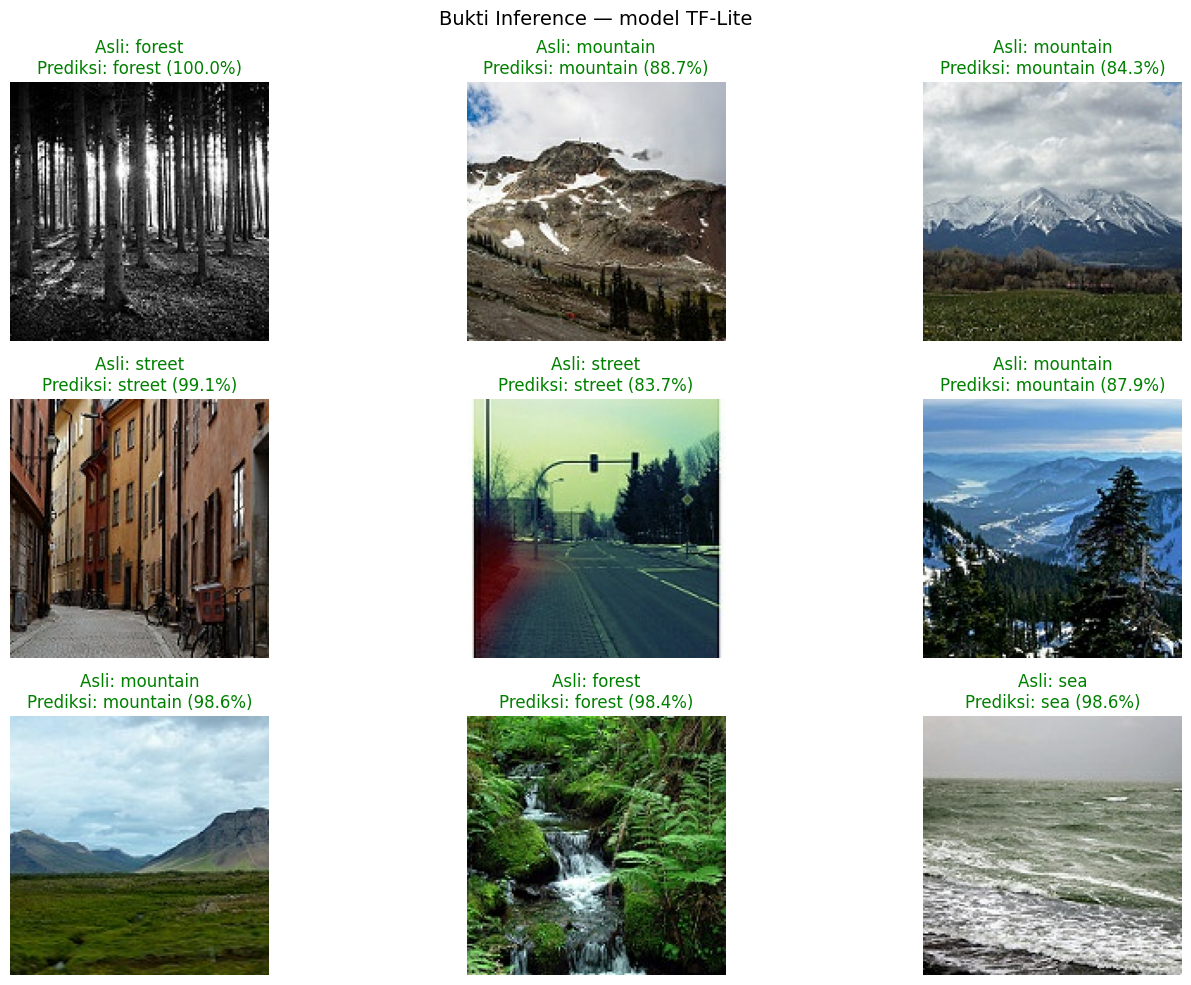

In [ ]:
interpreter = tf.lite.Interpreter(model_path='tflite/model.tflite')
interpreter.allocate_tensors()
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

for images, labels in test_ds.take(1):
    break

plt.figure(figsize=(15, 10))
for i in range(9):
    img = images[i].numpy()
    true_label = class_names[labels[i].numpy()]
    inp = np.expand_dims(img, axis=0).astype(np.float32)
    interpreter.set_tensor(input_details[0]['index'], inp)
    interpreter.invoke()
    pred = interpreter.get_tensor(output_details[0]['index'])
    pred_label = class_names[int(np.argmax(pred))]
    conf = float(np.max(pred)) * 100

    plt.subplot(3, 3, i + 1)
    plt.imshow(img)
    color = 'green' if pred_label == true_label else 'red'
    plt.title(f"Asli: {true_label}\nPrediksi: {pred_label} ({conf:.1f}%)", color=color)
    plt.axis('off')
plt.suptitle("Bukti Inference — model TF-Lite", fontsize=14)
plt.tight_layout()
plt.show()

### 13.2 Inference dengan SavedModel

In [ ]:
loaded = tf.saved_model.load('saved_model')
infer = loaded.signatures['serving_default']

sample_imgs = images[:5]
out = infer(tf.constant(sample_imgs))
key = list(out.keys())[0]
preds = out[key].numpy()

print("Hasil inference SavedModel:")
for i in range(5):
    true_label = class_names[labels[i].numpy()]
    pred_label = class_names[int(np.argmax(preds[i]))]
    conf = float(np.max(preds[i])) * 100
    status = "✅" if pred_label == true_label else "❌"
    print(f"{status} Asli: {true_label:10s} | Prediksi: {pred_label:10s} ({conf:.1f}%)")

Hasil inference SavedModel:
✅ Asli: forest     | Prediksi: forest     (100.0%)
✅ Asli: mountain   | Prediksi: mountain   (86.3%)
✅ Asli: mountain   | Prediksi: mountain   (84.3%)
✅ Asli: street     | Prediksi: street     (99.2%)
✅ Asli: street     | Prediksi: street     (88.1%)


## 14. Membuat requirements.txt

In [ ]:
libraries = ["tensorflow", "tensorflowjs", "numpy", "matplotlib", "pillow", "kagglehub"]
import importlib.metadata as ilm
name_map = {"pillow": "Pillow"}
lines = []
for lib in libraries:
    try:
        lines.append(f"{lib}=={ilm.version(name_map.get(lib, lib))}")
    except Exception:
        lines.append(lib)
with open('requirements.txt', 'w') as f:
    f.write('\n'.join(lines) + '\n')
print('\n'.join(lines))

tensorflow==2.19.0
tensorflowjs==4.22.0
numpy==2.0.2
matplotlib==3.10.0
pillow==11.3.0
kagglehub==1.0.2
